# **Hypothesis Testing on Medical Insurance Data**

Insurers decide how to price and approve policies from customer attributes such as age, sex, BMI, smoking status, and region. This notebook uses hypothesis testing to check whether some of those attributes are linked to differences in BMI, charges, or smoking rates, using the 1,338 customers in the dataset.

It walks through four tests: a two-tailed t-test, a one-tailed t-test, a one-way ANOVA, and a chi-square test of independence. Each follows the same steps: choose a statistic, state the hypotheses, set the significance level, and interpret the result. This is a first look at the data, before any predictive modelling.

## **Setup**

Libraries used:

*   `pandas` and `numpy` for data handling and numerical work.
*   `seaborn` and `matplotlib` for plots.
*   `scipy.stats` and `statsmodels` for the statistical tests.

Install them from `requirements.txt` into the project's `.venv` (see the README) and select that environment as the kernel.

In [1]:
import warnings 
warnings.filterwarnings('ignore')

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import requests

import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
from scipy.stats import chi2_contingency

from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

%matplotlib inline


## **The data**

`insurance.csv` holds age, sex, BMI, number of children, smoker status, region, and the charges billed to the insurer for each customer. The first cell below downloads it if there is no local copy.

The first five rows:

In [3]:
URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML0232EN-SkillsNetwork/asset/insurance.csv'

# Find the project's data folder whether the notebook is run from notebooks/, the project folder, or the repo root.
candidates = [Path('../data'), Path('data'), Path('projects/insurance-hypothesis-testing/data')]
data_dir = next((p for p in candidates if p.parent.exists() and (p.parent / 'requirements.txt').exists()), Path('data'))
data_dir.mkdir(exist_ok=True)
csv_path = data_dir / 'insurance.csv'

# Download only when there is no local copy; an existing file is never overwritten.
if not csv_path.exists():
    response = requests.get(URL, timeout=30)
    response.raise_for_status()
    csv_path.write_bytes(response.content)

data = pd.read_csv(csv_path)
data.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Column types and missing values:

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


Summary statistics for the numeric columns:

In [5]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


`charges` is the response variable. `age`, `sex`, `bmi`, `children`, `smoker`, and `region` are the predictors we examine.

## **The testing procedure**

## Does BMI differ between males and females?

### 1. Choose a sample statistic


The first step is to choose a sample statistic. Let μ₁ be the population mean BMI of males and μ₂ the population mean BMI of females. We compare the two means with a two-sample t-test.

### 2. Define hypothesis (Null and Alternative)


Next we state the hypotheses. The null hypothesis (H₀) says any difference in the observed means is due to chance. The alternative hypothesis (Hₐ) says there is a real difference.

$ 𝐻_{0}:\mu_{1}-\mu_{2} = 0 $ There is no difference between the BMI of male and BMI of female. \
$ 𝐻_{A}:\mu_{1}-\mu_{2} \ne 0 $ There is a difference between the BMI of male and BMI of female.


The ≠ in the alternative hypothesis makes this a two-tailed test.

### 3. Set the decision criteria


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML0232EN-SkillsNetwork/asset/Hypothesis_Testing_3.png)


We set the significance level at 5% (α = 0.05). `ttest_ind` returns a two-tailed p-value, so we compare it directly with α: if it is below α, we reject the null hypothesis. The right level depends on how costly a wrong decision is for the business.

Which test fits depends on the question:

*   **t-test**: compares means when the population standard deviation is unknown. It is the usual choice for two groups.
*   **z-test**: compares means or proportions when the population standard deviation is known, or with large samples.
*   **F-test**: compares variances, and is the basis of ANOVA.
*   **Chi-square test**: checks whether observed counts in a contingency table differ from the counts expected if the variables were independent.

### 4. Evaluate and interpret the result

Split the data into female and male customers:

In [7]:
female=data.loc[data.sex=="female"]
male=data.loc[data.sex=="male"]

Select the BMI values for each group:

In [8]:
f_bmi = female.bmi
m_bmi = male.bmi

In [9]:
m_bmi

1       33.770
2       33.000
3       22.705
4       28.880
8       29.830
         ...  
1324    25.935
1325    33.535
1327    30.030
1329    38.600
1333    30.970
Name: bmi, Length: 676, dtype: float64

Compare the BMI distributions for the two groups:

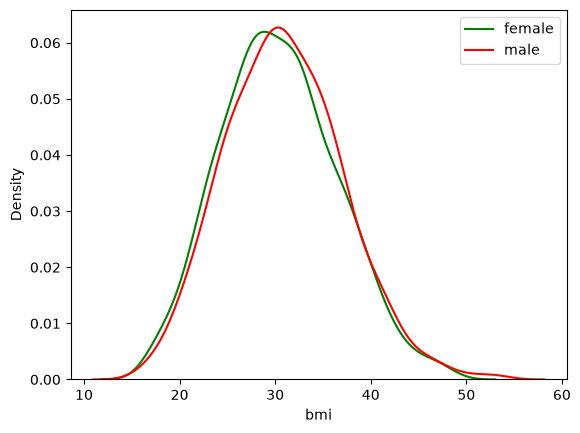

In [10]:
sns.kdeplot(f_bmi, color='green', label='female')
sns.kdeplot(m_bmi, color='red', label='male')
plt.legend()
plt.show()


The two distributions look very similar.

Mean BMI for each group:

In [11]:
female.bmi.mean()


np.float64(30.37774924471299)

In [12]:
male.bmi.mean()

np.float64(30.943128698224854)

Now the t-statistic and p-value, from `scipy.stats.ttest_ind`:

In [13]:
alpha=0.05
t_value1, p_value1 = stats.ttest_ind(m_bmi, f_bmi)
print("t_value1 = ",t_value1, ", p_value1 = ", p_value1)

t_value1 =  1.696752635752224 , p_value1 =  0.0899763717898493


A short if/else turns the p-value into a decision:

In [14]:
if p_value1 < alpha:
    print("Conclusion: since p_value {} is less than alpha {} ".format(p_value1, alpha))
    print("Reject the null hypothesis that there is no difference between bmi of females and bmi of males.")

else:
    print("Conclusion: since p_value {} is greater than alpha {} ".format(p_value1, alpha))
    print("Fail to reject the null hypothesis that there is no difference between bmi of females and bmi of males.")


Conclusion: since p_value 0.0899763717898493 is greater than alpha 0.05 
Fail to reject the null hypothesis that there is no difference between bmi of females and bmi of males.


Conclusion: We fail to reject the null hypothesis. There is not enough evidence to conclude that female and male BMI differ. This is not proof that the means are equal: it means the observed difference in sample means (about 0.57) is small enough to be plausible by chance alone.

## Do smokers have higher charges than non-smokers?

We compare mean charges for smokers and non-smokers, starting with the group means.

In [15]:
smoker = data.loc[data.smoker=="yes"]
smoker_char = smoker.charges
sch_mean = smoker_char.mean()
sch_mean

np.float64(32050.23183153284)

In [16]:
nonsmoker = data.loc[data.smoker=="no"]
nonsmoker_char = nonsmoker.charges

Mean charges for non-smokers:

In [17]:
nonsmoker_char_mean = nonsmoker_char.mean()
nonsmoker_char_mean


np.float64(8434.268297856204)

The hypotheses:

$ 𝐻_{0}:\mu_{1} \leq \mu_{2} $ The average charges of smokers are less than or equal to those of nonsmokers. \
$ 𝐻_{A}:\mu_{1} > \mu_{2} $ The average charges of smokers are greater than those of nonsmokers.


The ">" in the alternative hypothesis makes this a right-tailed test. We use a t-test, and we reject the null hypothesis if the t-statistic falls far enough into the right tail.

A boxplot of charges by smoking status:

[Text(0.5, 1.0, 'Fig:1 Smoker vs Charges')]

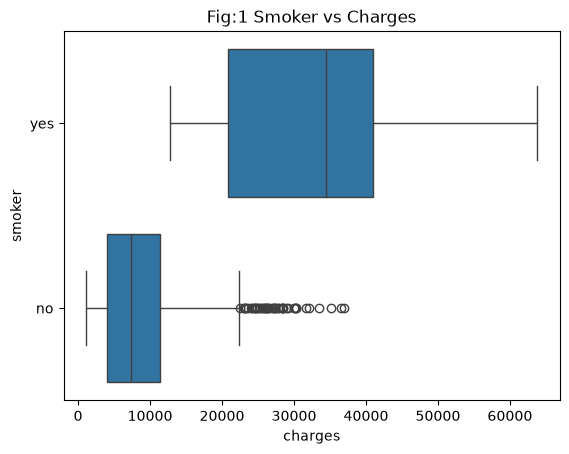

In [18]:
sns.boxplot(x=data.charges,y=data.smoker,data=data).set(title="Fig:1 Smoker vs Charges")

The t-statistic and p-value:

In [19]:
alpha = 0.05
# alternative='greater' runs the right-tailed test directly (H_A: mean charges of smokers > nonsmokers).
t_val2, p_value_onetail = stats.ttest_ind(smoker_char, nonsmoker_char, alternative='greater')
print("t_value = {} , p_value_onetail = {}".format(t_val2, p_value_onetail))


t_value = 46.66492117272371 , p_value_onetail = 4.1357179210893543e-283


**Conclusion**

In [20]:
if p_value_onetail < alpha:
    print("Reject the null hypothesis.")
    print("There is sufficient evidence to conclude that smokers have higher average charges than nonsmokers.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence to conclude that smokers have higher average charges than nonsmokers.")


Reject the null hypothesis.
There is sufficient evidence to conclude that smokers have higher average charges than nonsmokers.


## Does BMI differ for women with 0, 1, or 2 children?

The hypotheses:

$ 𝐻_{0}:\mu_{1}=\mu_{2}=\mu_{3} $ The mean BMI of women with no children , one child, and two children are the same. \
$ 𝐻_{A}: $ At least one of the means for women's BMI is not the same.


With three groups we use a one-way ANOVA (an F-test) at α = 0.05. First, filter to women with 0, 1, or 2 children.

In [21]:
female_children = female.loc[female['children']<=2]

Mean BMI by number of children:

In [22]:
female_children.groupby('children')['bmi'].mean()


children
0    30.361522
1    30.052658
2    30.649790
Name: bmi, dtype: float64

A boxplot of BMI by number of children:

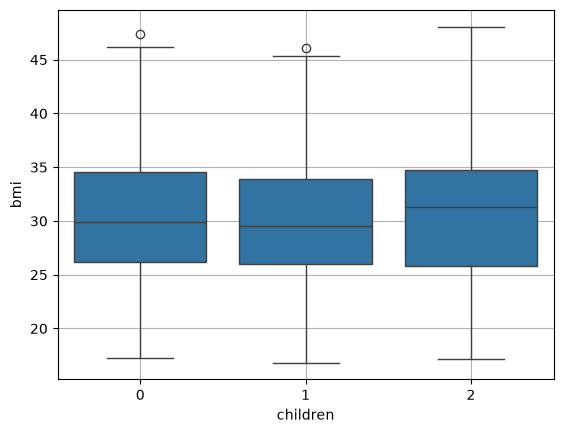

In [23]:
sns.boxplot(x="children", y="bmi", data=female_children)
plt.grid()
plt.show()


The ANOVA table comes from an ordinary least squares (OLS) model of BMI on number of children.

In [24]:
formula = 'bmi ~ C(children)'
model = ols(formula, female_children).fit()
aov_table = anova_lm(model)
aov_table

,df,sum_sq,mean_sq,F,PR(>F)
C(children),2.0,24.590123,12.295062,0.334472,0.715858
Residual,563.0,20695.661583,36.759612,NaN,NaN


Conclusion. p-value is 0.715858 and it is greater than the alpha (0.05), therefore we fail to reject the null hypothesis and conclude that the mean bmi of women with no children, one child, and two children are the same.


## Does the share of smokers differ by region?

The hypotheses:

$ 𝐻_{0} $: Smokers proportions are not significantly different across the different regions. \
$ 𝐻_{A} $: Smokers proportions are different across the different regions.


Both variables, smoker status and region, are categorical, so we use a chi-square test of independence.

First, a contingency table of region against smoker status, using `pd.crosstab`:

In [25]:
contingency= pd.crosstab(data.region, data.smoker)
contingency

smoker,no,yes
region,,
northeast,257,67
northwest,267,58
southeast,273,91
southwest,267,58


The same counts as a bar chart:

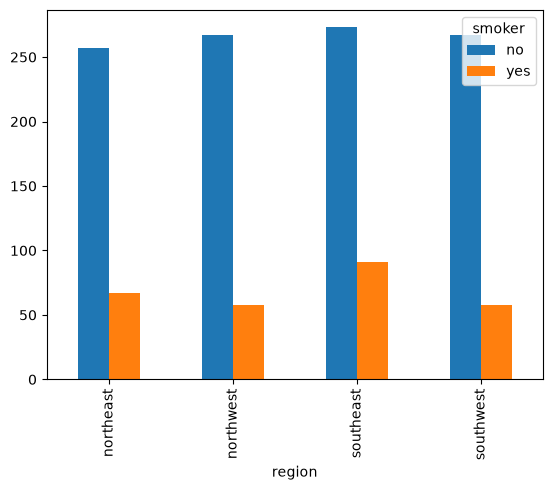

In [26]:
contingency.plot(kind='bar')
plt.show()


`chi2_contingency` returns the chi-square statistic, p-value, degrees of freedom, and expected frequencies:

In [27]:
chi2, p_val, dof, exp_freq = chi2_contingency(contingency, correction = False)
print('chi-square statistic: {} , p_value: {} , degree of freedom: {} ,expected frequencies: {} '.format(chi2, p_val, dof, exp_freq))

chi-square statistic: 7.343477761407071 , p_value: 0.06171954839170543 , degree of freedom: 3 ,expected frequencies: [[257.65022422  66.34977578]
 [258.44544096  66.55455904]
 [289.45889387  74.54110613]
 [258.44544096  66.55455904]] 


**Conclusion**

In [28]:
if p_val < 0.05:
    print('Reject the null hypothesis: the proportions of smokers differ significantly across regions.')
else:
    print('Fail to reject the null hypothesis: there is not enough evidence that the proportions of smokers differ across regions.')


Fail to reject the null hypothesis: there is not enough evidence that the proportions of smokers differ across regions.


p = 0.062 is above α = 0.05, so we fail to reject the null hypothesis: there is not enough evidence that the share of smokers differs by region. The result is close to the threshold, so it is borderline rather than strong evidence of no difference.

## Source

Adapted from the IBM Skills Network *Hypothesis Testing* lab (author: Svitlana Kramar). Copyright © 2020 IBM Corporation.